<a href="https://colab.research.google.com/github/mdnazishpatel/BiteCount-frontend/blob/main/Neuralnwork_Classification_PyTorch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Neural Network Classification with pytorch

Classification is a problem of predicting wether something is one thing or another(There can be multiple data aslo ( cat, pizza, dog, etc))

In [1]:
import sklearn
from sklearn.datasets import make_circles

# Making 1000 samples
n_samples = 1000

# Creating circles
x,y = make_circles(n_samples,
                   noise=0.3,
                   random_state=42)

In [2]:
len(x), len(y)

(1000, 1000)

In [3]:
print(f"first 5 samples of x {x[:5]}")
print(f"first 5 samples of y {y[:5]}")

first 5 samples of x [[ 0.59171471  0.43674853]
 [-0.45745002  0.36160118]
 [-1.01069349  0.83042101]
 [-0.87169639  0.41407292]
 [ 0.48803455 -0.87258708]]
first 5 samples of y [1 1 1 1 0]


In [4]:
#Making data frames of circles data
import pandas as pd
circles = pd.DataFrame({"x1": x[:, 0],
                        "x2": x[:, 1],
                        "label": y})
circles.head(10)

,x1,x2,label
0,0.591715,0.436749,1
1,-0.457450,0.361601,1
2,-1.010693,0.830421,1
3,-0.871696,0.414073,1
4,0.488035,-0.872587,0
5,-0.347874,1.103071,1
6,-0.046008,0.834056,1
7,0.610994,0.306608,1
8,-0.255312,-0.879601,1
9,0.025255,1.300938,0


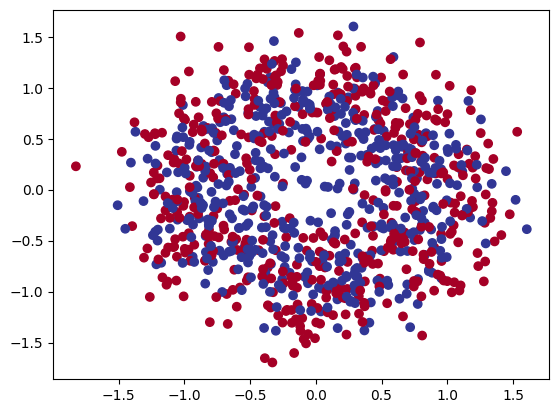

In [5]:
# Visualizing the data
import matplotlib.pyplot as plt
plt.scatter(x=x[:, 0],
            y=x[:, 1],
            c=y,
            cmap=plt.cm.RdYlBu)

### checking inputs and outputs shapes

In [6]:
x.shape, y.shape

((1000, 2), (1000,))

In [7]:
x

array([[ 0.59171471,  0.43674853],
       [-0.45745002,  0.36160118],
       [-1.01069349,  0.83042101],
       ...,
       [-0.01985814, -1.02765007],
       [ 0.54269168, -1.11429774],
       [ 0.24539316,  1.01154823]], shape=(1000, 2))

In [8]:
x_sample = x[0]
y_sample = y[0]

print(f"values for one sample of x:{x_sample} and the same for y: {y_sample}")
print(f"shape for one sample of x:{x_sample.shape} and the ssame for y: {y_sample.shape}")


values for one sample of x:[0.59171471 0.43674853] and the same for y: 1
shape for one sample of x:(2,) and the ssame for y: ()


### Turning data into tensors

In [9]:
import torch

torch.__version__

'2.14.1+cpu'

In [27]:
x = torch.as_tensor(x, dtype=torch.float32)
y = torch.as_tensor(y, dtype=torch.float32)
x[:5], y[:5]

(tensor([[ 0.5917,  0.4367],
         [-0.4575,  0.3616],
         [-1.0107,  0.8304],
         [-0.8717,  0.4141],
         [ 0.4880, -0.8726]]),
 tensor([1., 1., 1., 1., 0.]))

In [11]:
type(x), x.dtype, y.dtype

(torch.Tensor, torch.float32, torch.float32)

In [12]:
## Spliting the data into training and test sets

from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x,
                                                    y,
                                                    test_size=0.2,# here we divided data into (80% training data and 20% testing data)
                                                    random_state=42)

In [13]:
len(x_train), len(x_test),len(y_train), len(y_test)

(800, 200, 800, 200)

In [14]:
n_samples

1000

### Building a model
to classify our red and blue dots

In [15]:
import torch
from torch import nn

#agnostic code
device = "GPU" if torch.cuda.is_available() else "cpu"
device

'cpu'

In [16]:
x_train

tensor([[ 0.9182, -0.2022],
        [ 0.2415, -0.7090],
        [-1.1883,  0.1117],
        ...,
        [-0.1818, -1.3062],
        [ 1.2124,  0.3283],
        [ 0.5835, -0.5225]])

## Creating a model and to do that

1. subclasses `nn.module`
2. create 2 `nn.Linear()`
3. Define a `forward()`
Instatiate an instance of our model class and send it to the target `device`

In [28]:
class CircleModelV0(nn.Module):
  def __init__(self):
    super().__init__()
#nn.linear is a capable of handling the shapes of our data
    self.layer_1 = nn.Linear(in_features=2, out_features=5)#takes in 2 feactures and upscales to 5 feactures
    self.layer_2 = nn.Linear(in_features=5, out_features=1)# takes in 5 feactures from previous layer and outputs a single feacture(same shape as y)
  def forward(self, x):
    return self.layer_2(self.layer_1(x))# x->layer_1 -> layer_2 -> output

model_0 = CircleModelV0()

model_0


CircleModelV0(
  (layer_1): Linear(in_features=2, out_features=5, bias=True)
  (layer_2): Linear(in_features=5, out_features=1, bias=True)
)

In [18]:
## Replicating above model (writes forward class itself)
model_0 = nn.Sequential(
    nn.Linear(in_features=2, out_features=5),
    nn.Linear(in_features=5, out_features=1)
)
model_0

Sequential(
  (0): Linear(in_features=2, out_features=5, bias=True)
  (1): Linear(in_features=5, out_features=1, bias=True)
)

In [19]:
model_0.state_dict()

OrderedDict([('0.weight',
              tensor([[-0.6021, -0.6096],
                      [-0.1648, -0.5740],
                      [ 0.3154,  0.4991],
                      [-0.2580, -0.6677],
                      [-0.3255,  0.4079]])),
             ('0.bias', tensor([-0.6264, -0.0027,  0.1725, -0.2209, -0.5251])),
             ('1.weight',
              tensor([[-0.3361, -0.0332,  0.0167,  0.1632,  0.4122]])),
             ('1.bias', tensor([-0.3270]))])

In [20]:
# Making predictions on untrained model
with torch.inference_mode():
  untrained_preds = model_0(x_test)
print(f"length of preds {len(untrained_preds)}, shape:{untrained_preds.shape}")
print(f"length of test samples: {len(x_test)}, shape: {x_test.shape}")
print(f"\nfirst 10 preds: \n {torch.round(untrained_preds[:10])}")
print(f"\nfirst 10 labels:\n {y_test[:10]}")


length of preds 200, shape:torch.Size([200, 1])
length of test samples: 200, shape: torch.Size([200, 2])

first 10 preds: 
 tensor([[-0.],
        [-0.],
        [-0.],
        [-0.],
        [-1.],
        [-1.],
        [-0.],
        [-0.],
        [-1.],
        [-0.]])

first 10 labels:
 tensor([1., 0., 1., 0., 1., 1., 0., 0., 1., 0.])


In [21]:

## Setup loss function and optimizer
loss_fn = nn.BCEWithLogitsLoss() #build in sigmoid func and more stable then BCELoss

optimizer = torch.optim.SGD(params=model_0.parameters(),
                            lr=0.1)


In [33]:
##Calculate accuracy
def accuracy_fn(y_true, y_preds):
  correct = torch.eq(y_true, y_preds).sum().item()
  acc = (correct/len(y_preds)) * 100
  return acc
# print(acc)

### Training our model
* Forward pass
* Calculate loss
* Optimizer zero grad
* Loss backward(backpropagation)
*  step (Gradient desent)

### Going from raw logits -> Prediction Probabilities -> Prediction labels

**logits** : our model raw outputs are called logits
we can convert this into prediction probabilities by passing them to some kind of activation function (sigmoid, binary crossentropy and softmax for multiclassification)

In [23]:

model_0.eval()
with torch.inference_mode():
  y_logits = model_0(x_test)[:5]
y_logits

tensor([[-0.2099],
        [-0.1653],
        [-0.4312],
        [-0.0177],
        [-0.7558]])

In [24]:
##Using sigmoid  activation fun on our logits to turn them into preds
## y_preds_probs >= 0.5 (y=1), (class 1)
## y_preds_probs <= 0.5 (y=0), (class 0)
y_preds_probs = torch.sigmoid(y_logits)
y_preds_probs.round()

tensor([[0.],
        [0.],
        [0.],
        [0.],
        [0.]])

In [25]:
## Find the predicts labels
y_preds = torch.round(y_preds_probs)
#In full (logits -> pred prob -> pred labels)
y_preds_labels = torch.round(torch.sigmoid(model_0(x_test)[:5]))
print(torch.eq(y_preds.squeeze(), y_preds_labels.squeeze()))

y_preds.squeeze()

tensor([True, True, True, True, True])


tensor([0., 0., 0., 0., 0.])

In [34]:
torch.manual_seed(42)
epoches = 100
x_train, y_train = x_train, y_train
x_test, y_test = x_test, y_test
for epoch in range(epoches):
  #starting the training loop
  model_0.train()
  #forward pass
  y_logits = model_0(x_train).squeeze()
  y_preds = torch.round(torch.sigmoid(y_logits))
  #Calculating loss
  loss = loss_fn(y_logits,
                 y_train)
  #Calculating accuracy
  acc = accuracy_fn(y_true=y_train,
                    y_preds=y_preds)
  #Setting grad zero
  optimizer.zero_grad
  #Backpropagatation
  loss.backward()
  #Gradient descent
  optimizer.step()

  model_0.eval()
  with torch.inference_mode():
    test_logits = model_0(x_test).squeeze()
    test_preds = torch.round(torch.sigmoid(test_logits))

    test_loss = loss_fn(test_logits,
                        y_test)
    test_acc = accuracy_fn(y_true = y_test,
                        y_preds = test_preds)

    if epoch % 10 ==0:
      print(f"Epoch: {epoch}|Loss: {loss:.5f}, Acc: {acc:.2f} % | Test loss: {test_loss:.5f}, Test acc: {test_acc:.2f}%")


Epoch: 0|Loss: 0.69584, Acc: 50.00 % | Test loss: 0.69741, Test acc: 50.00%
Epoch: 10|Loss: 0.69584, Acc: 50.00 % | Test loss: 0.69741, Test acc: 50.00%
Epoch: 20|Loss: 0.69584, Acc: 50.00 % | Test loss: 0.69741, Test acc: 50.00%
Epoch: 30|Loss: 0.69584, Acc: 50.00 % | Test loss: 0.69741, Test acc: 50.00%
Epoch: 40|Loss: 0.69584, Acc: 50.00 % | Test loss: 0.69741, Test acc: 50.00%
Epoch: 50|Loss: 0.69584, Acc: 50.00 % | Test loss: 0.69741, Test acc: 50.00%
Epoch: 60|Loss: 0.69584, Acc: 50.00 % | Test loss: 0.69741, Test acc: 50.00%
Epoch: 70|Loss: 0.69584, Acc: 50.00 % | Test loss: 0.69741, Test acc: 50.00%
Epoch: 80|Loss: 0.69584, Acc: 50.00 % | Test loss: 0.69741, Test acc: 50.00%
Epoch: 90|Loss: 0.69584, Acc: 50.00 % | Test loss: 0.69741, Test acc: 50.00%
